# P3: Acquisition & Integration

**DSA 405**

**Lindsey Ramsey**

## Project Overview

My project analyzes how average hourly wages across eight U.S. industries changed relative to inflation between 2015 and 2025. The overall goal is to find whether wage growth consistently rose with inflation, as well as detecting if these patterns differed across industries.

My Two datasets:

1. **Bureau of Labor Statistics (BLS):** Monthly average hourly earnings for eight U.S. industries, which I audited and cleaned during P2.
2. **Federal Reserve Economic Data (FRED):** Monthly Consumer Price Index (CPIAUCSL) data, which measures changes in consumer prices over time.


In [1]:

import pandas as pd
import numpy as np
import requests
import time
from pathlib import Path
from io import BytesIO
RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
HEADERS = {"User-Agent": "DSA405-student-coursework (NC State; educational project)"}
print("Successful")
print("Ready.")


Successful
Ready.


In [2]:
from google.colab import files
import io

uploaded = files.upload()

filename = next(iter(uploaded))
merged_df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    parse_dates=["date"]
)

print("Successfully loaded!", merged_df.shape)
display(merged_df.head())


Saving bls_cpi_merged_verified.csv to bls_cpi_merged_verified.csv
Successfully loaded! (1056, 10)


,series_id,industry,year,period,period_name,hourly_earnings,month,date,CPIAUCSL,_merge
0,CES2000000003,Construction,2024,M12,December,38.94,12,2024-12-01,317.604,both
1,CES2000000003,Construction,2024,M11,November,38.77,11,2024-11-01,316.528,both
2,CES2000000003,Construction,2024,M10,October,38.69,10,2024-10-01,315.631,both
3,CES2000000003,Construction,2024,M09,September,38.55,9,2024-09-01,314.732,both
4,CES2000000003,Construction,2024,M08,August,38.34,8,2024-08-01,314.062,both


In [3]:
print(merged_df.columns.tolist())
display(merged_df.head())
print(merged_df["date"].min(), merged_df["date"].max())

['series_id', 'industry', 'year', 'period', 'period_name', 'hourly_earnings', 'month', 'date', 'CPIAUCSL', '_merge']


,series_id,industry,year,period,period_name,hourly_earnings,month,date,CPIAUCSL,_merge
0,CES2000000003,Construction,2024,M12,December,38.94,12,2024-12-01,317.604,both
1,CES2000000003,Construction,2024,M11,November,38.77,11,2024-11-01,316.528,both
2,CES2000000003,Construction,2024,M10,October,38.69,10,2024-10-01,315.631,both
3,CES2000000003,Construction,2024,M09,September,38.55,9,2024-09-01,314.732,both
4,CES2000000003,Construction,2024,M08,August,38.34,8,2024-08-01,314.062,both


2015-01-01 00:00:00 2025-12-01 00:00:00


Comparing: 2015-01-01 to 2025-12-01

Real wage growth by industry:
industry
Private Education and Health Services     3.58
Manufacturing                             4.04
Trade, Transportation, and Utilities      5.50
Construction                              7.56
Professional and Business Services        8.70
Financial Activities                     11.95
Information                              12.39
Leisure and Hospitality                  18.31
dtype: float64


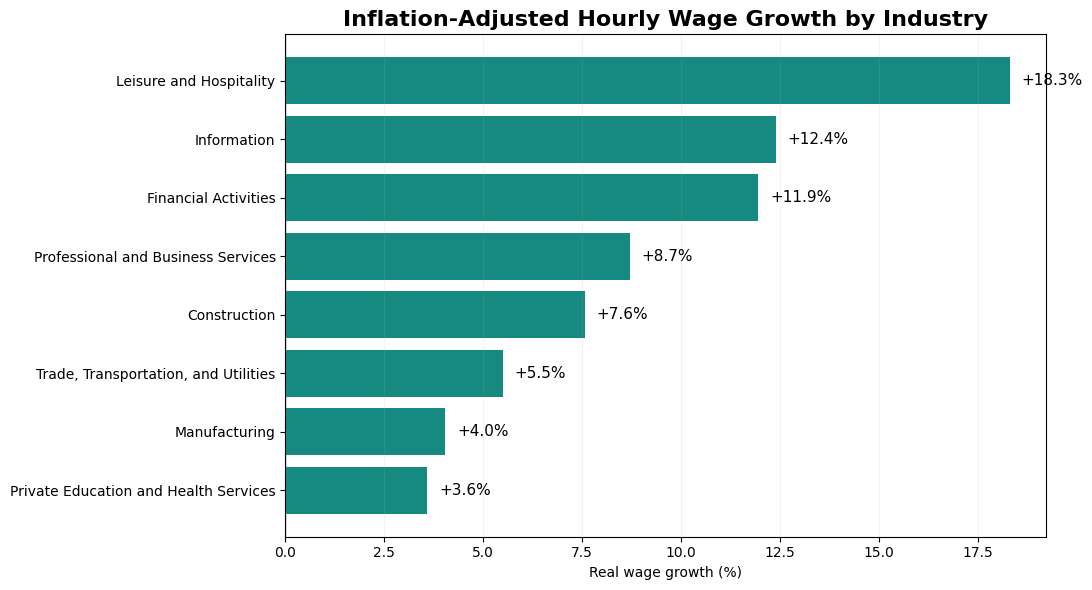


Highest growth: Leisure and Hospitality (18.31%)
Lowest growth: Private Education and Health Services (3.58%)


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = merged_df.copy()

df["date"] = pd.to_datetime(df["date"])
df["hourly_earnings"] = pd.to_numeric(df["hourly_earnings"])
df["CPIAUCSL"] = pd.to_numeric(df["CPIAUCSL"])

# Compare the first and last available months
valid = df.dropna(subset=["hourly_earnings", "CPIAUCSL"])
start = valid["date"].min()
end = valid["date"].max()

print("Comparing:", start.date(), "to", end.date())

# Calculate real wages
valid = valid.copy()
valid["real_wage"] = (
    valid["hourly_earnings"] / valid["CPIAUCSL"]
)

# Calculate real wage growth by industry
comparison = valid[
    valid["date"].isin([start, end])
].pivot(
    index="industry",
    columns="date",
    values="real_wage"
)

# Ensure every industry has both endpoint values
comparison = comparison.dropna()

growth = (
    (comparison[end] / comparison[start] - 1) * 100
).sort_values()

print("\nReal wage growth by industry:")
print(growth.round(2))

# Graph
plt.figure(figsize=(11, 6))

colors = [
    "#168A80" if x >= 0 else "#C45A54"
    for x in growth
]

bars = plt.barh(growth.index, growth.values, color=colors)

plt.axvline(0, color="gray", linewidth=1)

for bar, value in zip(bars, growth):
    plt.text(
        value + (0.3 if value >= 0 else -0.3),
        bar.get_y() + bar.get_height()/2,
        f"{value:+.1f}%",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=11
    )

plt.title(
    "Inflation-Adjusted Hourly Wage Growth by Industry",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Real wage growth (%)")
plt.grid(axis="x", alpha=0.15)
plt.tight_layout()

plt.savefig(
    "slide3_real_wage_growth.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nHighest growth:", growth.idxmax(),
      f"({growth.max():.2f}%)")
print("Lowest growth:", growth.idxmin(),
      f"({growth.min():.2f}%)")

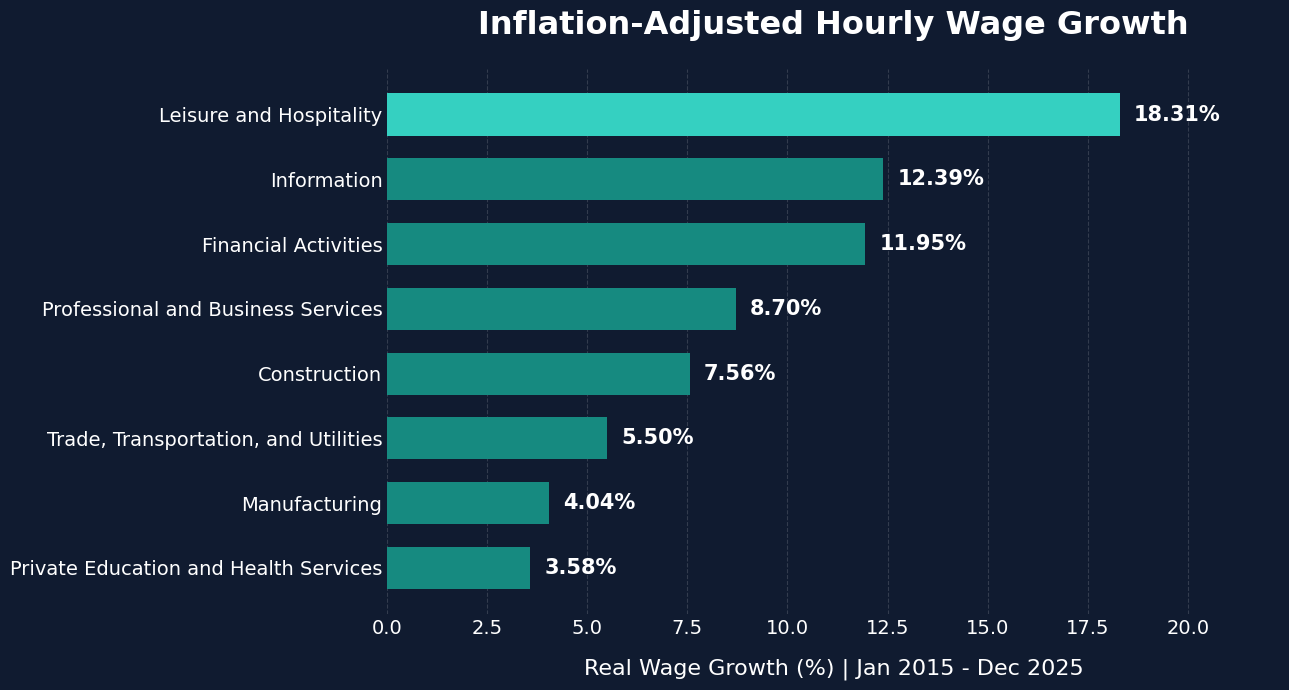

In [5]:

import matplotlib.pyplot as plt

# Dark presentation theme
fig, ax = plt.subplots(figsize=(13, 7))
fig.patch.set_facecolor("#101B30")
ax.set_facecolor("#101B30")

# Teal bars, with brightest color for highest growth
colors = [
    "#35D0C1" if industry == growth.idxmax() else "#168A80"
    for industry in growth.index
]

bars = ax.barh(
    growth.index,
    growth.values,
    color=colors,
    height=0.65
)

# Make all text white and large
ax.set_title(
    "Inflation-Adjusted Hourly Wage Growth",
    color="white",
    fontsize=23,
    fontweight="bold",
    pad=25
)

ax.set_xlabel(
    "Real Wage Growth (%) | Jan 2015 - Dec 2025",
    color="white",
    fontsize=16,
    labelpad=15
)

ax.tick_params(
    axis="both",
    colors="white",
    labelsize=14,
    length=0
)

# White percentages at the ends of the bars
for bar, value in zip(bars, growth.values):
    ax.text(
        value + 0.35,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        color="white",
        fontsize=15,
        fontweight="bold",
        va="center"
    )

# Subtle gridlines
ax.grid(
    axis="x",
    color="white",
    alpha=0.15,
    linestyle="--"
)
ax.set_axisbelow(True)

# Remove borders
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlim(0, growth.max() + 4)

plt.tight_layout()

# Save high-resolution graph
plt.savefig(
    "slide3_wage_growth_dark.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


## 1. Data Acquisition

### 1.1 CPI Data from FRED

The CPI dataset is retrieved from the FRED CSV. The acquisition function checks for a cached file before making a new request, also uses a timeout, and validates the response.

The dataset contains 132 monthly observations from January 2015 to December 2025. The raw CSV is saved in data/raw/.

In [9]:
import pandas as pd
from google.colab import files
import io

uploaded = files.upload()

filename = next(iter(uploaded))

cpi_raw = pd.read_csv(io.BytesIO(uploaded[filename]))

print("FRED data loaded successfully!")
display(cpi_raw.head())
print(cpi_raw.columns.tolist())


Saving CPIAUCSL.csv to CPIAUCSL.csv
FRED data loaded successfully!


,observation_date,CPIAUCSL
0,2015-01-01,234.747
1,2015-02-01,235.342
2,2015-03-01,235.976
3,2015-04-01,236.222
4,2015-05-01,237.001


['observation_date', 'CPIAUCSL']


In [10]:

cpi_check = cpi_raw.copy()
if "DATE" in cpi_check.columns:
    cpi_check = cpi_check.rename(columns={"DATE": "observation_date"})

cpi_check["date"] = pd.to_datetime(cpi_check["observation_date"], errors="raise")
cpi_check["CPIAUCSL"] = pd.to_numeric(cpi_check["CPIAUCSL"], errors="raise")
print("Total observations:", len(cpi_check))
print("Earliest date:", cpi_check["date"].min())
print("Latest date:", cpi_check["date"].max())
print("Missing values:")
print(cpi_check.isna().sum())
print("Duplicate dates:", cpi_check["date"].duplicated().sum())

start_date = pd.Timestamp("2015-01-01")
end_date = pd.Timestamp("2025-12-01")
if cpi_check["date"].min() > start_date:
    raise ValueError("CPI data does not include January 2015.")

if cpi_check["date"].max() < end_date:
    raise ValueError("CPI data does not include December 2025.")

print("CPI data contains the required period.")
display(cpi_check.head())


Total observations: 132
Earliest date: 2015-01-01 00:00:00
Latest date: 2025-12-01 00:00:00
Missing values:
observation_date    0
CPIAUCSL            1
date                0
dtype: int64
Duplicate dates: 0
CPI data contains the required period.


,observation_date,CPIAUCSL,date
0,2015-01-01,234.747,2015-01-01
1,2015-02-01,235.342,2015-02-01
2,2015-03-01,235.976,2015-03-01
3,2015-04-01,236.222,2015-04-01
4,2015-05-01,237.001,2015-05-01


### Acquisition Error Handling

During my first few attempts, the FRED CSV endpoint timed out with both 30 second and 60 second limits. There is code included that raises an error for this event.

To avoid repeated requests, the notebook uses a cached CPI file included in the uploads area of Colab. The validation function also checks whether the data is empty or missing required columns.

I also tested the validation function with an incorrect CSV to show that it detects incorrect data and notify the user that it failed.

In [11]:
invalid_cpi = b"observation_date,WRONG_COLUMN\n2025-01-01,100\n"
try:
    validate_cpi(invalid_cpi)
    raise AssertionError("Incorrect CPI data was incorrectly accepted.")
except ValueError as e:
    print("Failure identified:", e)

Failure identified: A column = missing.


## 2. Ethics and Legality

For this project, I used publicly available economic data from the Bureau of Labor Statistics and Federal Reserve Economic Data. Neither source required a login or payment, also, the datasets do not contain personally identifiable information.

In my A8 acquisition plan, I planned to use the BLS Public Data API and downloading CPI data as a CSV file from FRED. My P3 followed this plan, however, with a necessary change. After experiencing timeouts when requesting the FRED data, I used a cached CSV file to avoid unnecessary repeated requests.

The 4 legal/ethical categories in A8:

- Hacking (CFAA): The project does not access restricted systems nor require authentication.
- Contract (Terms of Service): I reviewed the source terms in A8 and identified the requirement to provide credit to BLS and FRED.
- Circumvention: The acquisition process does not bypass paywalls, access restrictions, or other technical protections.
- Privacy: The datasets do not have information about identifiable individuals.

#### Actions Taken:
The code utilizes an User-Agent, request timeouts, and caching. I saved the raw CPI data and documented the missing October 2025 CPI observation rather than changing it.

Overall, the acquisition approach remained mostly consistent with my A8 plan, and the project uses public data without the need to bypass any access restrictions.

In [14]:
import pandas as pd
from google.colab import files
import io

print("Upload your cleaned BLS wage data CSV")

uploaded = files.upload()
filename = next(iter(uploaded))

bls_clean = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    parse_dates=["date"]
)

print("BLS data loaded successfully!")
print("Shape:", bls_clean.shape)
display(bls_clean.head())

Upload your cleaned BLS wage data CSV


Saving bls_hourly_earnings_cleaned.csv to bls_hourly_earnings_cleaned (1).csv
BLS data loaded successfully!
Shape: (1056, 8)


,series_id,industry,year,period,period_name,hourly_earnings,month,date
0,CES2000000003,Construction,2024,M12,December,38.94,12,2024-12-01
1,CES2000000003,Construction,2024,M11,November,38.77,11,2024-11-01
2,CES2000000003,Construction,2024,M10,October,38.69,10,2024-10-01
3,CES2000000003,Construction,2024,M09,September,38.55,9,2024-09-01
4,CES2000000003,Construction,2024,M08,August,38.34,8,2024-08-01


In [17]:
from google.colab import files
from pathlib import Path
import pandas as pd
import io
uploaded = files.upload()
filename = next(iter(uploaded))

PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

bls_clean = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    parse_dates=["date"])

BLS_PATH = PROCESSED_DIR / "bls_hourly_earnings_cleaned.csv"
bls_clean.to_csv(BLS_PATH, index=False)

print("BLS data loaded successfully!")
print("Shape:", bls_clean.shape)
display(bls_clean.head())

Saving bls_hourly_earnings_cleaned.csv to bls_hourly_earnings_cleaned (2).csv
BLS data loaded successfully!
Shape: (1056, 8)


,series_id,industry,year,period,period_name,hourly_earnings,month,date
0,CES2000000003,Construction,2024,M12,December,38.94,12,2024-12-01
1,CES2000000003,Construction,2024,M11,November,38.77,11,2024-11-01
2,CES2000000003,Construction,2024,M10,October,38.69,10,2024-10-01
3,CES2000000003,Construction,2024,M09,September,38.55,9,2024-09-01
4,CES2000000003,Construction,2024,M08,August,38.34,8,2024-08-01


In [18]:

print("BLS date range:")
print(bls_clean["date"].min(), "to", bls_clean["date"].max())

print("CPI date range:")
print(cpi_check["date"].min(), "to", cpi_check["date"].max())

print("BLS unique industries:", bls_clean["industry"].nunique())

print("BLS unique months:", bls_clean["date"].nunique())

print("CPI unique months:", cpi_check["date"].nunique())

print("Duplicate BLS industry-date combinations:", bls_clean.duplicated(subset=["industry", "date"]).sum())
print("Duplicate CPI dates:", cpi_check["date"].duplicated().sum())
missing_dates = (set(bls_clean["date"]) - set(cpi_check["date"]))
print("BLS dates missing from CPI:", len(missing_dates))
if missing_dates:
    print("Missing dates:", sorted(missing_dates))


BLS date range:
2015-01-01 00:00:00 to 2025-12-01 00:00:00
CPI date range:
2015-01-01 00:00:00 to 2025-12-01 00:00:00
BLS unique industries: 8
BLS unique months: 132
CPI unique months: 132
Duplicate BLS industry-date combinations: 0
Duplicate CPI dates: 0
BLS dates missing from CPI: 0


## 3. Join Design

| Join Keys | Answer |
|---|---|
| Join key | date |
| Grain of left table | One row per industry per month |
| Grain of right table | One row per month |
| Relationship | Many-to-one |
| Expected row count after join | 1,056 |
| Join type | Left join |
| What happens to the Unmatched rows | Kept with missing CPI values |


#### Why Many-To-One
A many-to-one relationship is most expected because the BLS dataset contains many industry observations for one month, but the CPI dataset only has one observation per month.

#### Join Type and Why
I selected a left join because the BLS wage observations are the main focus of my project. An inner join might delete BLS observations if a month was missing from the CPI dataset. A left join saves these observations and shows the missing CPI matches.

The merge will use validate="many_to_one" to ensure that the CPI dataset does not have duplicate monthly values. This helps prevent a fan out join, where a single BLS observation might incorrectly match more than one CPI records.

The expected result is 1,056 rows, as each CPI month is unique.

In [19]:
cpi_merge = cpi_check[["date", "CPIAUCSL"]].copy()
assert cpi_merge["date"].is_unique, ("CPI has duplicate dates!!!")
merged_df = pd.merge(bls_clean, cpi_merge, on="date", how="left", validate="many_to_one", indicator=True)
print("BLS rows before merge:", len(bls_clean))
print("Rows after merge:", len(merged_df))
print("Merge results:")
print(merged_df["_merge"].value_counts())
print("Merged dataset:")
display(merged_df.head())


BLS rows before merge: 1056
Rows after merge: 1056
Merge results:
_merge
both          1056
left_only        0
right_only       0
Name: count, dtype: int64
Merged dataset:


,series_id,industry,year,period,period_name,hourly_earnings,month,date,CPIAUCSL,_merge
0,CES2000000003,Construction,2024,M12,December,38.94,12,2024-12-01,317.604,both
1,CES2000000003,Construction,2024,M11,November,38.77,11,2024-11-01,316.528,both
2,CES2000000003,Construction,2024,M10,October,38.69,10,2024-10-01,315.631,both
3,CES2000000003,Construction,2024,M09,September,38.55,9,2024-09-01,314.732,both
4,CES2000000003,Construction,2024,M08,August,38.34,8,2024-08-01,314.062,both


## 4. Verification Suite

After combining the BLS hourly earnings data with the FRED Consumer Price Index data, I enforced a verification suite to check whether the merge performed correctly and produced the expected results.

The checks consist of validating row count preservation, unique industry date combinations, unique CPI key, missing matches, and valid CPI values.

These assertions are important because a merge can cause incorrect results and not show an error. For instance, duplicate dates in the CPI dataset could increase BLS observations, but missing CPI dates could leave wage values without connected inflation data.

In [20]:
# This ensures that the merge does not add or delete any rows.
assert len(merged_df) == len(bls_clean), ("Row count changed during the merge.")
# This protects duplicate industry month records.
assert not merged_df.duplicated(subset=["industry", "date"]).any(), ("Duplicate industry-date combinations found.")
# Makes sure that CPI dates are unique / no duplicate matches.
assert cpi_merge["date"].is_unique, ("CPI dates are not unique.")
# Ensures there are not unmatched dates.
assert (merged_df["_merge"] == "both").all(), ("Some BLS dates did not match CPI dates.")
# Checks that all CPI values are positive.
assert (merged_df["CPIAUCSL"].dropna() > 0).all(), ("Invalid CPI values found.")

# Makes sure that missing CPI values are in the same months as the source data.
source_missing_dates = set(cpi_merge.loc[cpi_merge["CPIAUCSL"].isna(), "date"])
merged_missing_dates = set(merged_df.loc[merged_df["CPIAUCSL"].isna(), "date"])
assert merged_missing_dates == source_missing_dates, ("Merged CPI missing dates differ from source.")

# Confirms that the 8 missing CPI values found are present.
assert merged_df["CPIAUCSL"].isna().sum() == 8, ("Unexpected number of missing CPI values.")

print("6/6 Pass")
print("Rows preserved:", len(merged_df))
print("Unique industries:", merged_df["industry"].nunique())
print("Unique months:", merged_df["date"].nunique())
print("Missing CPI values:", merged_df["CPIAUCSL"].isna().sum())
print("Missing CPI month(s):", sorted(merged_missing_dates))


6/6 Pass
Rows preserved: 1056
Unique industries: 8
Unique months: 132
Missing CPI values: 8
Missing CPI month(s): [Timestamp('2025-10-01 00:00:00')]


### 4. Verification Results and Missing Data

The verification suite confirmed that the integration kept all 1,056 BLS observations without creating duplicate industry-month combinations. All BLS dates successfully matched dates in the CPI dataset.

However, the first verification showed 8 missing CPI values in the merged dataset. After I spent time reviewing my code and data, it showed that these missing values were from a missing CPI observation for October 2025 in the original FRED CSV file.

Because the BLS dataset contains eight industries for each month, the  missing CPI observation was presented in eight merged rows.

I chose to keep these missing values rather than replace them with estimated CPI values or delete the related wage observations to maintain the original source data and ensure that estimated values did not affect my analysis.

The revised verification suite verfies that the missing values are consistent with the source dataset, also checks row preservation, unique keys, successful date matching, and valid nonmissing CPI values.

For any calculations requiring CPI, the eight affected observations will need to be deleted from those calculations or handled with a different method.

## 5. Surprising Finding

One unexpected finding during the integration process includes that having matching dates between two datasets does not ensure that the corresponding data values are fully complete.

Although all 1,056 BLS observations matched a date in the CPI dataset, eight records still contained missing CPI values. This happened since the October 2025 CPI record was included in the source file but did not have a reported CPI value. This finding showed why simply just checking only row counts and successful join matches is not the best way to verify that the merge was successful, or find an error. Additional verification of actual data values was quite necessary to ensure that an integrated dataset is ready for analysis. It also presented the importance of preserving missing data and documenting its impact instead of filling in missing values.

In [21]:
VERIFIED_PATH = (PROCESSED_DIR / "bls_cpi_merged_verified.csv")

merged_df.to_csv(VERIFIED_PATH, index=False)

print("Verified dataset saved successfully!")
print("File:", VERIFIED_PATH)
print("Shape:", merged_df.shape)
print("Missing CPI values:", merged_df["CPIAUCSL"].isna().sum())


Verified dataset saved successfully!
File: data/processed/bls_cpi_merged_verified.csv
Shape: (1056, 10)
Missing CPI values: 8


In [22]:
from google.colab import files

files.download("data/processed/bls_cpi_merged_verified.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Self-Scored Rubric

| Criterion | Wt | The short version |
|---|---|---|
| Acquisition code | 2 | Retrieves reliably, rate-limited, cached, and fails loudly, with one demonstrated catch |
| Ethics & legality in practice | 2 | Matches the A8 plan; drift documented |
| Join design | 2 | Keys and cardinality stated **before** the merge; alternatives ruled out |
| **Verification suite** | **3** | three or more assertions |
| Reproducibility & readability | 0.5 | Runs without errors, readable by a peer, README updated |

## P4: Final Analysis and Findings

This section presents how inflation-adjusted hourly wages changed
across eight major U.S. industries from 2015 to 2025.
The goal is to identify which industries experienced the greatest
and smallest real wage growth.

In [23]:
print("Dataset shape:", merged_df.shape)
print("\nColumns:")
print(merged_df.columns.tolist())

print("\nFirst five rows:")
display(merged_df.head())

print("\nMissing values:")
print(merged_df.isna().sum())

Dataset shape: (1056, 10)

Columns:
['series_id', 'industry', 'year', 'period', 'period_name', 'hourly_earnings', 'month', 'date', 'CPIAUCSL', '_merge']

First five rows:


,series_id,industry,year,period,period_name,hourly_earnings,month,date,CPIAUCSL,_merge
0,CES2000000003,Construction,2024,M12,December,38.94,12,2024-12-01,317.604,both
1,CES2000000003,Construction,2024,M11,November,38.77,11,2024-11-01,316.528,both
2,CES2000000003,Construction,2024,M10,October,38.69,10,2024-10-01,315.631,both
3,CES2000000003,Construction,2024,M09,September,38.55,9,2024-09-01,314.732,both
4,CES2000000003,Construction,2024,M08,August,38.34,8,2024-08-01,314.062,both



Missing values:
series_id          0
industry           0
year               0
period             0
period_name        0
hourly_earnings    0
month              0
date               0
CPIAUCSL           8
_merge             0
dtype: int64


In [24]:
missing_cpi = merged_df[merged_df["CPIAUCSL"].isna()]

print("Rows with missing CPI:")
display(missing_cpi[["industry", "date", "CPIAUCSL"]])

print("\nDates with missing CPI:")
print(missing_cpi["date"].unique())

Rows with missing CPI:


,industry,date,CPIAUCSL
962,Construction,2025-10-01,NaN
974,Manufacturing,2025-10-01,NaN
986,"Trade, Transportation, and Utilities",2025-10-01,NaN
998,Information,2025-10-01,NaN
1010,Financial Activities,2025-10-01,NaN
1022,Professional and Business Services,2025-10-01,NaN
1034,Private Education and Health Services,2025-10-01,NaN
1046,Leisure and Hospitality,2025-10-01,NaN



Dates with missing CPI:
<DatetimeArray>
['2025-10-01 00:00:00']
Length: 1, dtype: datetime64[ns]


In [25]:
analysis_df = merged_df.dropna(subset=["CPIAUCSL"]).copy()

print("Original rows:", len(merged_df))
print("Rows excluded:", len(merged_df) - len(analysis_df))
print("Rows remaining:", len(analysis_df))
print("Missing CPI values:", analysis_df["CPIAUCSL"].isna().sum())

Original rows: 1056
Rows excluded: 8
Rows remaining: 1048
Missing CPI values: 0


### Missing CPI Data

After merging the BLS hourly earnings data with the FRED CPI data, I found eight missing CPI values, all from October 2025. Each missing value represented one of the eight industries.

The Bureau of Labor Statistics was unable to collect its normal CPI survey data for October 2025 because of the federal government shutdown. Rather than estimate the missing values, therfore I excluded these eight observations from the final analysis.

This reduced the dataset from 1,056 to 1,048 observations.

### Calculating Inflation-Adjusted Hourly Wages

To compare wage growth across industries, I adjusted hourly earnings for inflation using the Consumer Price Index (CPI). This allows me to measure changes in purchasing power rather than just changes in dollar amounts.

I used the same calculation for all eight industries so that the results could be compared fairly.

In [26]:
analysis_df["real_hourly_wage"] = (analysis_df["hourly_earnings"] / analysis_df["CPIAUCSL"]) * 100

analysis_df = analysis_df.sort_values(["industry", "date"])
display(analysis_df[["industry", "date", "hourly_earnings", "CPIAUCSL", "real_hourly_wage"]].head(10))

print("Real wage calculations completed!")

,industry,date,hourly_earnings,CPIAUCSL,real_hourly_wage
119,Construction,2015-01-01,27.07,234.747,11.531564
118,Construction,2015-02-01,27.12,235.342,11.523655
117,Construction,2015-03-01,27.24,235.976,11.543547
116,Construction,2015-04-01,27.28,236.222,11.548459
115,Construction,2015-05-01,27.32,237.001,11.527378
114,Construction,2015-06-01,27.34,237.657,11.503974
113,Construction,2015-07-01,27.36,238.034,11.494156
112,Construction,2015-08-01,27.44,238.033,11.527813
111,Construction,2015-09-01,27.35,237.498,11.515886
110,Construction,2015-10-01,27.52,237.733,11.576012


Real wage calculations completed!


In [27]:
yearly_wages = (
    analysis_df[analysis_df["year"].isin([2015, 2025])]
    .groupby(["industry", "year"])["real_hourly_wage"]
    .mean()
    .unstack())

yearly_wages["real_wage_growth_pct"] = ((yearly_wages[2025] - yearly_wages[2015]) / yearly_wages[2015]) * 100
yearly_wages = yearly_wages.sort_values("real_wage_growth_pct", ascending=False)

display(yearly_wages.round(2))

year,2015,2025,real_wage_growth_pct
industry,,,
Leisure and Hospitality,6.04,7.09,17.33
Financial Activities,13.30,14.76,10.99
Information,14.81,16.31,10.13
Professional and Business Services,12.70,13.73,8.08
Construction,11.54,12.32,6.71
"Trade, Transportation, and Utilities",9.18,9.61,4.71
Private Education and Health Services,10.65,11.04,3.70
Manufacturing,10.65,11.00,3.31


In [28]:
comparison_df = analysis_df[analysis_df["year"].isin([2015, 2025])].copy()
months_2015 = set(comparison_df.loc[comparison_df["year"] == 2015, "month"])
months_2025 = set(comparison_df.loc[comparison_df["year"] == 2025, "month"])
common_months = sorted(months_2015 & months_2025)
print("Months used:", common_months)
comparison_df = comparison_df[comparison_df["month"].isin(common_months)]
yearly_wages = (comparison_df.groupby(["industry", "year"])["real_hourly_wage"].mean().unstack())
yearly_wages["real_wage_growth_pct"] = ((yearly_wages[2025] - yearly_wages[2015]) / yearly_wages[2015]) * 100

yearly_wages = yearly_wages.sort_values("real_wage_growth_pct", ascending=False)
display(yearly_wages.round(2))

Months used: [1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12]


year,2015,2025,real_wage_growth_pct
industry,,,
Leisure and Hospitality,6.04,7.09,17.38
Financial Activities,13.29,14.76,11.03
Information,14.80,16.31,10.23
Professional and Business Services,12.70,13.73,8.13
Construction,11.54,12.32,6.74
"Trade, Transportation, and Utilities",9.17,9.61,4.76
Private Education and Health Services,10.65,11.04,3.74
Manufacturing,10.64,11.00,3.35


### Visualizing Real Wage Growth by Industry

The following graph compares inflation-adjusted hourly wage growth across eight industries between 2015 and 2025. The comparison uses the same 11 months in each year because October 2025 CPI data was unavailable.

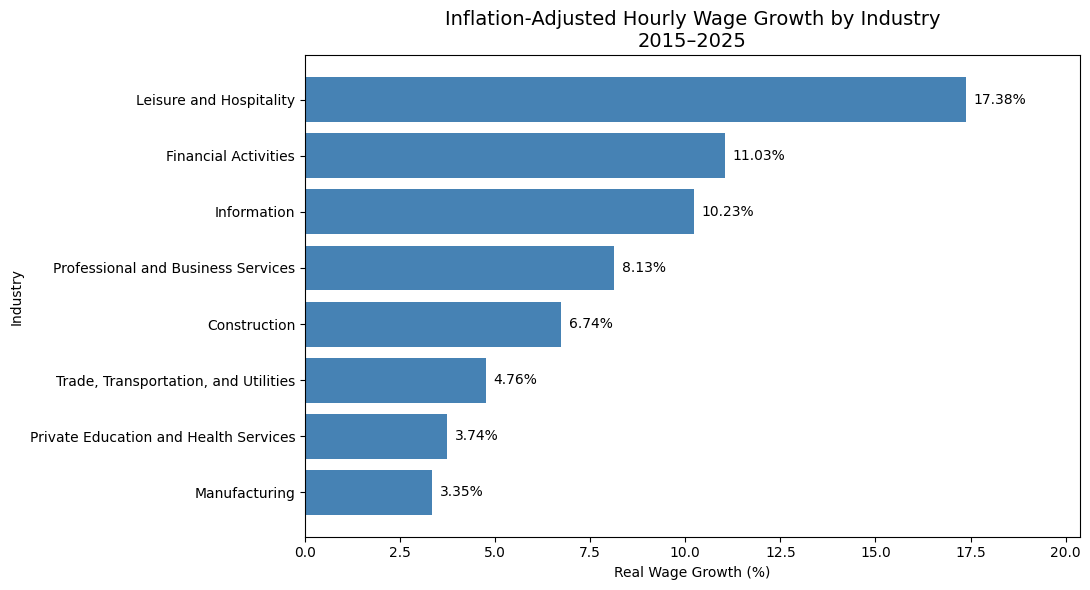

In [29]:
import matplotlib.pyplot as plt
growth = yearly_wages["real_wage_growth_pct"].sort_values()
plt.figure(figsize=(11, 6))
bars = plt.barh(growth.index, growth.values, color="steelblue")
for bar in bars:
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.2f}%", va="center")

plt.title("Inflation-Adjusted Hourly Wage Growth by Industry\n2015–2025", fontsize=14)
plt.xlabel("Real Wage Growth (%)")
plt.ylabel("Industry")
plt.xlim(0, growth.max() + 3)
plt.tight_layout()

plt.savefig("real_wage_growth_by_industry.png", dpi=300)
plt.show()

### Findings

The results show that all eight industries experienced positive inflation-adjusted hourly wage growth between 2015 and 2025. However, the amount of growth varied across industries.

Leisure and Hospitality experienced the greatest real wage growth at 17.38%, followed by Financial Activities at 11.03% and Information at 10.23%. Manufacturing experienced the smallest increase at 3.35%, followed by Private Education and Health Services at 3.74%.

One interesting finding is that Leisure and Hospitality had the highest percentage growth even though it had the lowest average inflation-adjusted hourly wage in both years. This suggests that an industry can experience strong wage growth while still having relatively low wages compared with other industries.

These findings describe changes in industry averages and do not necessarily mean that every worker in an industry experienced the same wage growth. The results also do not establish what caused the differences between industries.

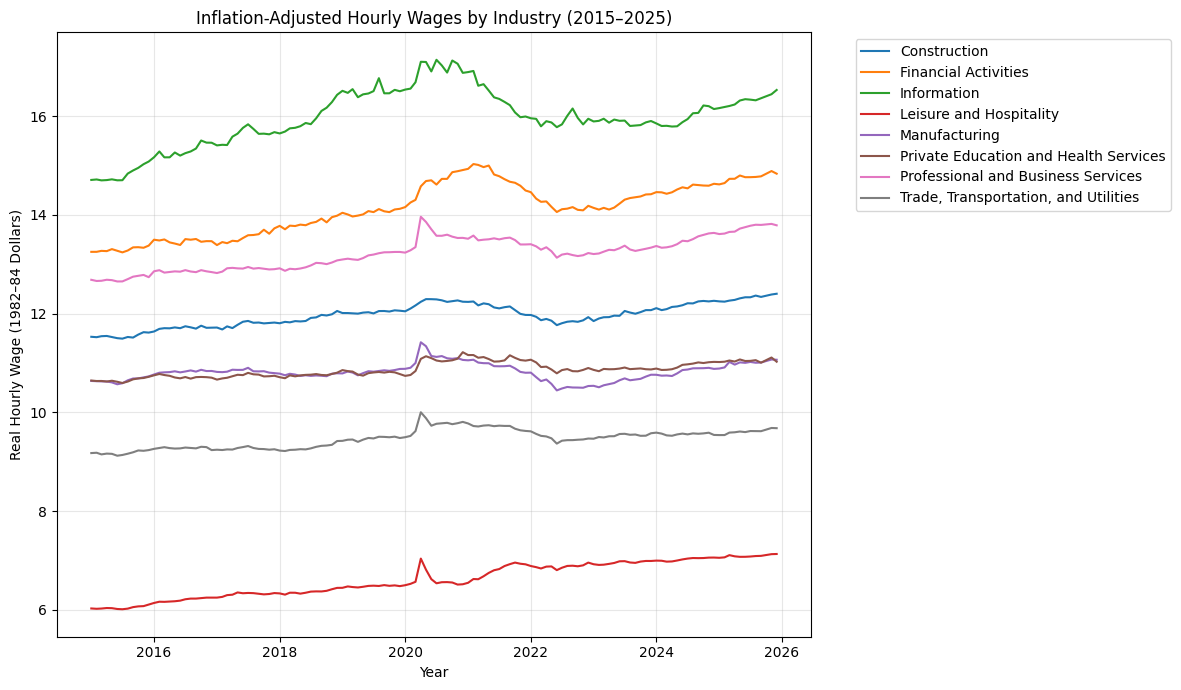

In [30]:
plt.figure(figsize=(12, 7))

for industry, group in analysis_df.groupby("industry"):
    group = group.sort_values("date")
    plt.plot(group["date"], group["real_hourly_wage"], label=industry)

plt.title("Inflation-Adjusted Hourly Wages by Industry (2015–2025)")
plt.xlabel("Year")
plt.ylabel("Real Hourly Wage (1982–84 Dollars)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("real_hourly_wages_over_time.png", dpi=300, bbox_inches="tight")
plt.show()